In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import xarray as xr
import scipy.stats as stats
from scipy.stats import skew
from tqdm import tqdm

mpl.rcParams['figure.dpi'] = 150
mpl.rcParams['pdf.fonttype'] = 42
mpl.rc('font', family='sans', weight='normal', size=12)

## Parameters

In [2]:
timespi  = ('1850', '1880')
timesfut = ('2070', '2100')

ninobox = [-5, 5, 190, 240]
latlon  = [-90, 90, 0, 360]

basedir = '/glade/work/smagahey/UCSB/codes/smile_data/'

# Model registry: display label -> file suffix
models = {
    'ACCESS-LENS':     'access_lens',
    'CanESM5-LENS':    'canesm5_lens',
    'CESM2-LENS':      'cesm2_lens',
    'IPSL-CM6A-LENS':  'ipsl_cm6a_lens',
    'MIROC6-LENS':     'miroc6_lens',
    'MIROC-ESM2L-LENS':'miroc_esm2l_lens',
    'E3SMv1-LENS':     'e3smv1_lens',
    'E3SMv2-LENS':     'e3smv2_lens',
}
colors = ['navy', 'yellowgreen', 'deepskyblue', 'crimson',
          'gold', 'darkorange', 'orchid', 'olive']

bins = np.linspace(-4, 4, 250)

## Load and process N34 for all models

For each model: load SST, area-average over Nino3.4, detrend by ensemble mean,
remove climatology, compute DJF seasonal mean.

In [3]:
def get_djf_n34(ds, varname, ninobox):
    """
    From a raw SST dataset, compute DJF Nino3.4 SSTA.
    Returns (member, year) DataArray.
    """
    da = ds[varname]
    # Area average over Nino3.4
    n34 = da.sel(
        lat=slice(ninobox[0], ninobox[1]),
        lon=slice(ninobox[2], ninobox[3])
    ).mean('lat').mean('lon').squeeze()

    # Detrend by ensemble mean
    n34 = n34 - n34.mean('member')

    # Remove monthly climatology
    clim = n34.groupby('time.month').mean()
    n34  = n34.groupby('time.month') - clim

    # DJF seasonal mean
    djf = n34.resample(time='QS-DEC').mean('time')
    djf = djf.where(djf.time.dt.month == 12, drop=True)

    return djf


n34_djf = {}   # n34_djf[label] -> (member, time) DJF timeseries

for label, suffix in tqdm(models.items()):
    print(f'Loading {label}...')
    fpath = (f'{basedir}tas_{latlon[0]}-{latlon[1]}N_'
             f'{latlon[2]}-{latlon[3]}E_{suffix}_ssp370.nc')
    h = (f'{basedir}tas_{latlon[0]}-{latlon[1]}N_'
                 f'{latlon[2]}-{latlon[3]}E_{suffix}_ssp370.nc')
    ds = xr.open_dataset(fpath)
    varname = 'tas'

    n34_djf[label] = get_djf_n34(ds, varname, ninobox)
    print(f'  {label}: {n34_djf[label].shape}')

print('Done.')

  0%|          | 0/8 [00:00<?, ?it/s]

Loading ACCESS-LENS...


 12%|█▎        | 1/8 [00:04<00:28,  4.01s/it]

  ACCESS-LENS: (40, 252)
Loading CanESM5-LENS...


 25%|██▌       | 2/8 [00:07<00:22,  3.80s/it]

...

  MIROC-ESM2L-LENS: (10, 252)
Loading E3SMv1-LENS...


 88%|████████▊ | 7/8 [00:14<00:01,  1.24s/it]

  E3SMv1-LENS: (15, 252)
Loading E3SMv2-LENS...


100%|██████████| 8/8 [00:14<00:00,  1.86s/it]

  E3SMv2-LENS: (10, 252)
Done.


## Compute KDEs for PI and Future periods

In [4]:
def pool_and_kde(djf, t1, t2):
    """
    Select time period, pool all members, return KDE and skewness.
    """
    subset = djf.sel(time=slice(t1, t2))
    vals   = subset.values.reshape(-1)
    vals   = vals[~np.isnan(vals)]
    kde    = stats.gaussian_kde(vals)
    sk     = skew(vals)
    return kde, sk


kdes_pi  = {}
kdes_fut = {}
skews_pi  = {}
skews_fut = {}


for label in models:
    kdes_pi[label],  skews_pi[label]  = pool_and_kde(n34_djf[label], timespi[0],  timespi[1])
    kdes_fut[label], skews_fut[label] = pool_and_kde(n34_djf[label], timesfut[0], timesfut[1])

print('Skewness PI: ', {k: f'{v:.3f}' for k, v in skews_pi.items()})
print('Skewness FUT:', {k: f'{v:.3f}' for k, v in skews_fut.items()})

Skewness PI:  {'ACCESS-LENS': '-0.234', 'CanESM5-LENS': '-0.085', 'CESM2-LENS': '-0.096', 'IPSL-CM6A-LENS': '0.129', 'MIROC6-LENS': '0.605', 'MIROC-ESM2L-LENS': '0.369', 'E3SMv1-LENS': '0.137', 'E3SMv2-LENS': '-0.089'}
Skewness FUT: {'ACCESS-LENS': '-0.274', 'CanESM5-LENS': '-0.020', 'CESM2-LENS': '-0.533', 'IPSL-CM6A-LENS': '0.167', 'MIROC6-LENS': '-0.220', 'MIROC-ESM2L-LENS': '0.158', 'E3SMv1-LENS': '-0.161', 'E3SMv2-LENS': '0.132'}


## 2-panel PDF plot: PI vs Future

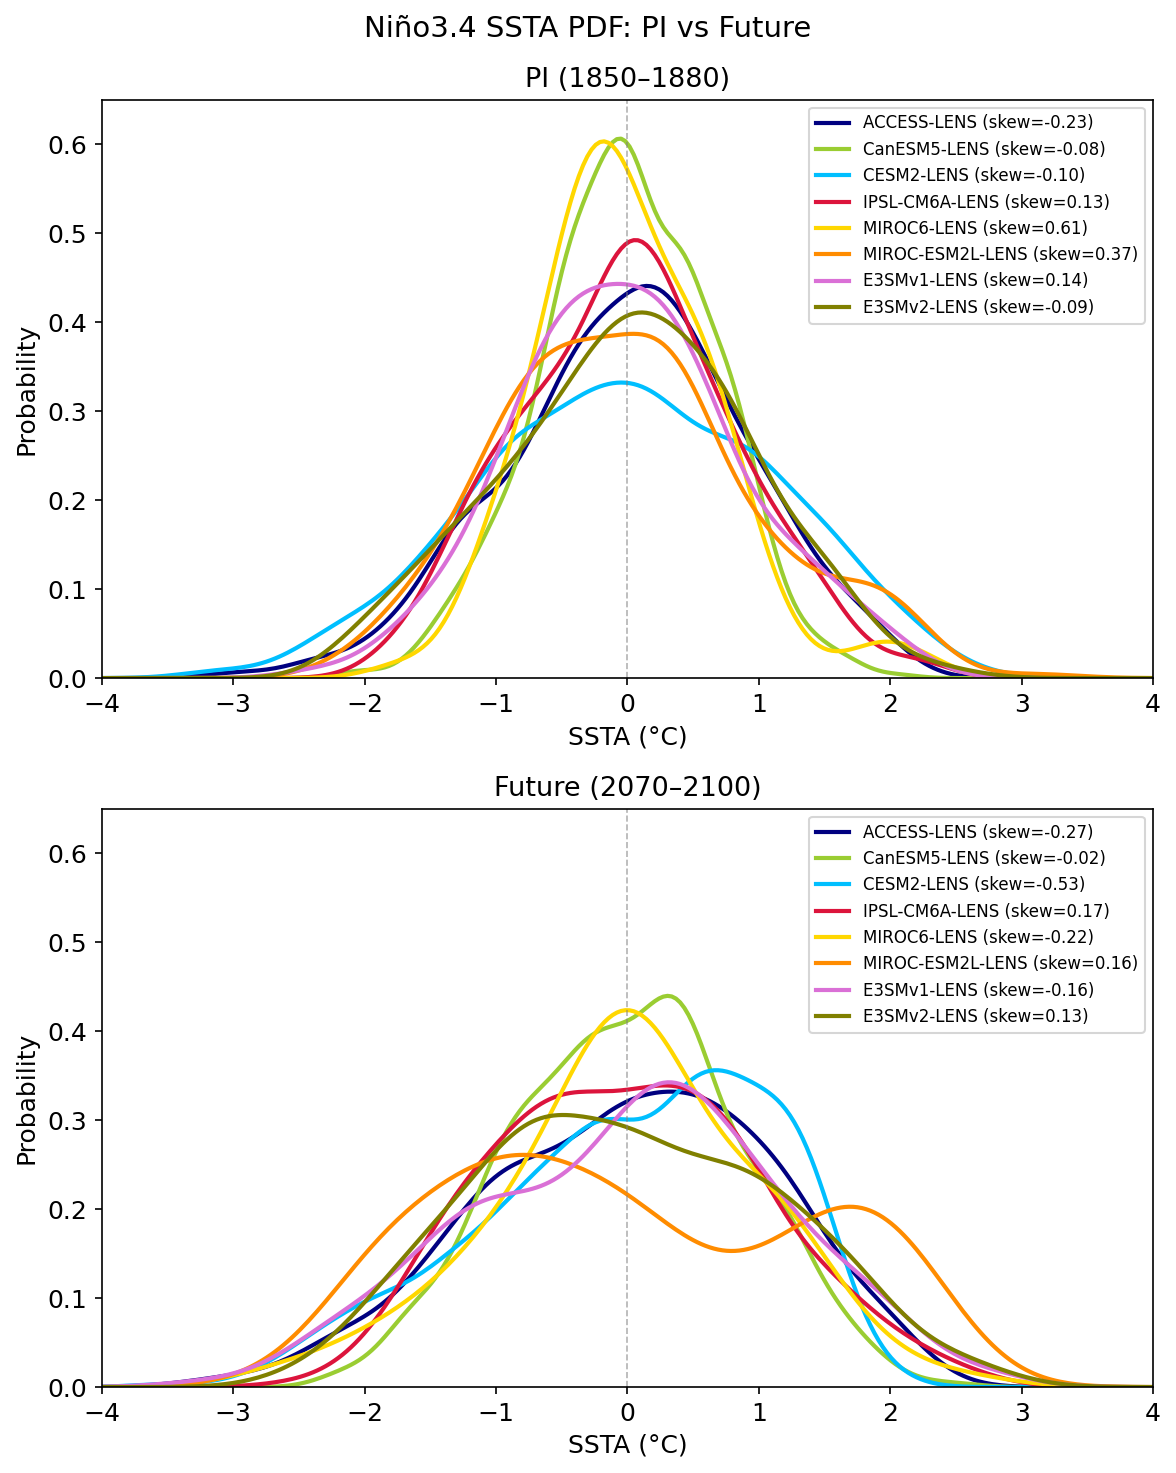

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(8,10))

panels = [
    (axes[0], kdes_pi,  skews_pi,  f'PI ({timespi[0]}–{timespi[1]})'),
    (axes[1], kdes_fut, skews_fut, f'Future ({timesfut[0]}–{timesfut[1]})'),
]

for ax, kdes, sks, title in panels:
    for (label, kde), color in zip(kdes.items(), colors):
        ax.plot(bins, kde(bins), lw=2, color=color,
                label=f'{label} (skew={sks[label]:.2f})')

    ax.axvline(0, color='gray', lw=0.8, ls='--', alpha=0.6)
    ax.set_xlim(-4, 4)
    ax.set_ylim(0, 0.65)
    ax.set_xlabel('SSTA (°C)')
    ax.set_ylabel('Probability')
    ax.set_title(title, fontsize=13)
    ax.legend(fontsize=8, loc='upper right')

fig.suptitle('Niño3.4 SSTA PDF: PI vs Future', fontsize=14)
plt.tight_layout()
plt.savefig('fig1.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
from statsmodels.stats.proportion import proportions_ztest

# threshold for La Nina / El Nino
LN_thresh = -1  # 1 sigma
EN_thresh  =  1

print(f"{'Model':20s}  {'LN PI%':>7} {'LN FUT%':>8} {'LN p':>7}    {'EN PI%':>7} {'EN FUT%':>8} {'EN p':>7}")
print('-' * 85)

for label in models:
    pi_vals  = n34_djf[label].sel(time=slice(timespi[0],  timespi[1])).values.reshape(-1)
    fut_vals = n34_djf[label].sel(time=slice(timesfut[0], timesfut[1])).values.reshape(-1)
    pi_vals  = pi_vals[~np.isnan(pi_vals)]
    fut_vals = fut_vals[~np.isnan(fut_vals)]

    # Count events in each tail
    ln_pi_n  = np.sum(pi_vals  < LN_thresh)
    ln_fut_n = np.sum(fut_vals < LN_thresh)
    en_pi_n  = np.sum(pi_vals  > EN_thresh)
    en_fut_n = np.sum(fut_vals > EN_thresh)

    # Proportions z-test: is the fraction in each tail significantly different?
    _, p_ln = proportions_ztest([ln_pi_n, ln_fut_n], [len(pi_vals), len(fut_vals)])
    _, p_en = proportions_ztest([en_pi_n, en_fut_n], [len(pi_vals), len(fut_vals)])

    ln_pi_pct  = ln_pi_n  / len(pi_vals)  * 100
    ln_fut_pct = ln_fut_n / len(fut_vals) * 100
    en_pi_pct  = en_pi_n  / len(pi_vals)  * 100
    en_fut_pct = en_fut_n / len(fut_vals) * 100

    sig_ln = '*' if p_ln < 0.05 else ' '
    sig_en = '*' if p_en < 0.05 else ' '

    print(f'{label:20s}  {ln_pi_pct:7.1f} {ln_fut_pct:8.1f} {p_ln:7.4f}{sig_ln}   '
          f'{en_pi_pct:7.1f} {en_fut_pct:8.1f} {p_en:7.4f}{sig_en}')

Model                  LN PI%  LN FUT%    LN p     EN PI%  EN FUT%    EN p
-------------------------------------------------------------------------------------
ACCESS-LENS              14.6     19.3  0.0019*      14.4     19.8  0.0004*
CanESM5-LENS              6.8     13.0  0.0000*       5.5     13.4  0.0000*
CESM2-LENS               18.8     19.1  0.8546       20.3     20.8  0.7223 
IPSL-CM6A-LENS           12.3     17.9  0.0422*      11.1     16.7  0.0356*
MIROC6-LENS               7.5     15.1  0.1048        5.4     17.2  0.0108*
MIROC-ESM2L-LENS         14.5     29.0  0.0000*      16.5     30.3  0.0000*
E3SMv1-LENS              12.3     22.2  0.0001*      13.3     20.0  0.0064*
E3SMv2-LENS              15.2     20.0  0.1135       13.2     22.3  0.0032*


In [7]:
pi_std = pi_vals.std()
pi_vals_norm  = pi_vals  / pi_std
fut_vals_norm = fut_vals / pi_std  # divide future by PI std too for consistent reference

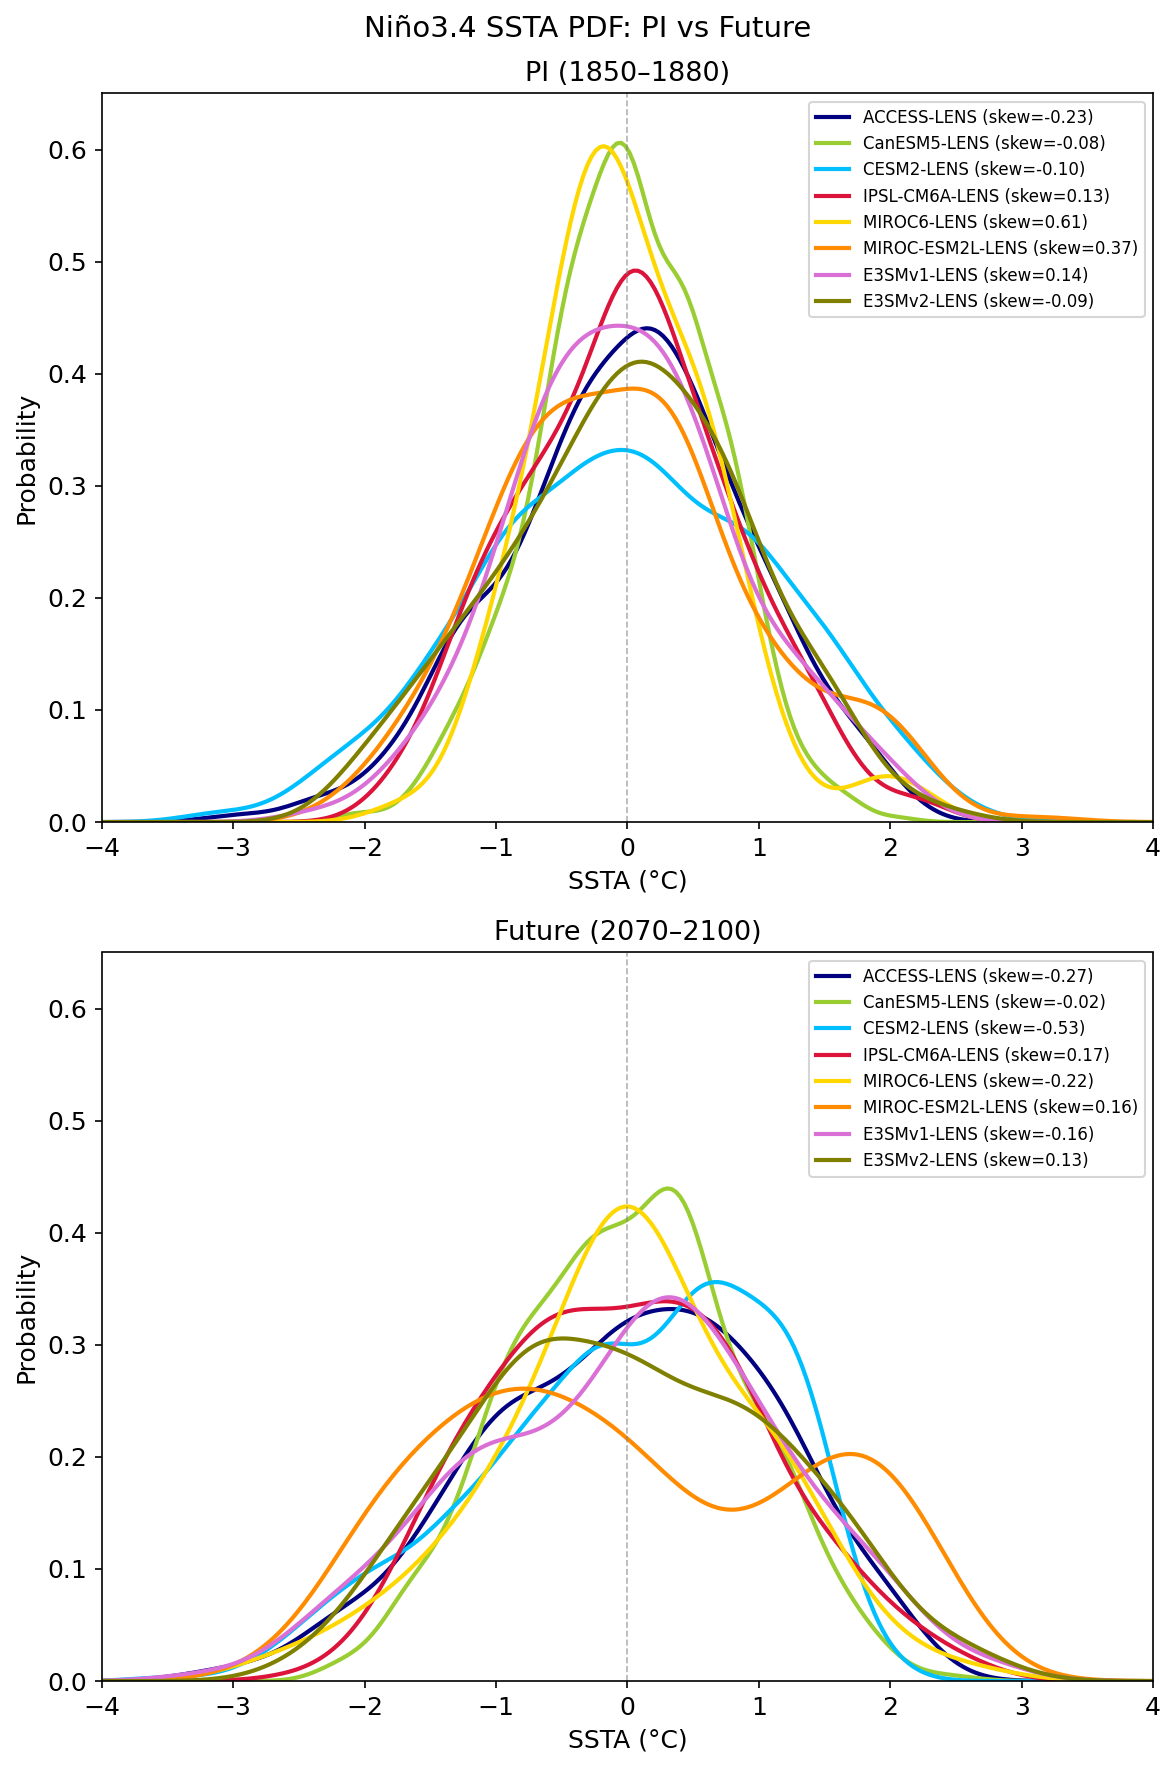

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(8,12))

panels = [
    (axes[0], kdes_pi,  skews_pi,  f'PI ({timespi[0]}–{timespi[1]})'),
    (axes[1], kdes_fut, skews_fut, f'Future ({timesfut[0]}–{timesfut[1]})'),
]

for ax, kdes, sks, title in panels:
    for (label, kde), color in zip(kdes.items(), colors):
        ax.plot(bins, kde(bins), lw=2, color=color,
                label=f'{label} (skew={sks[label]:.2f})')

    ax.axvline(0, color='gray', lw=0.8, ls='--', alpha=0.6)
    ax.set_xlim(-4, 4)
    ax.set_ylim(0, 0.65)
    ax.set_xlabel('SSTA (°C)')
    ax.set_ylabel('Probability')
    ax.set_title(title, fontsize=13)
    ax.legend(fontsize=8, loc='upper right')

fig.suptitle('Niño3.4 SSTA PDF: PI vs Future', fontsize=14)
plt.tight_layout()
plt.savefig('n34_pdf_pi_vs_fut.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
styles=['-','--','-.',':','-','--','-.',':']

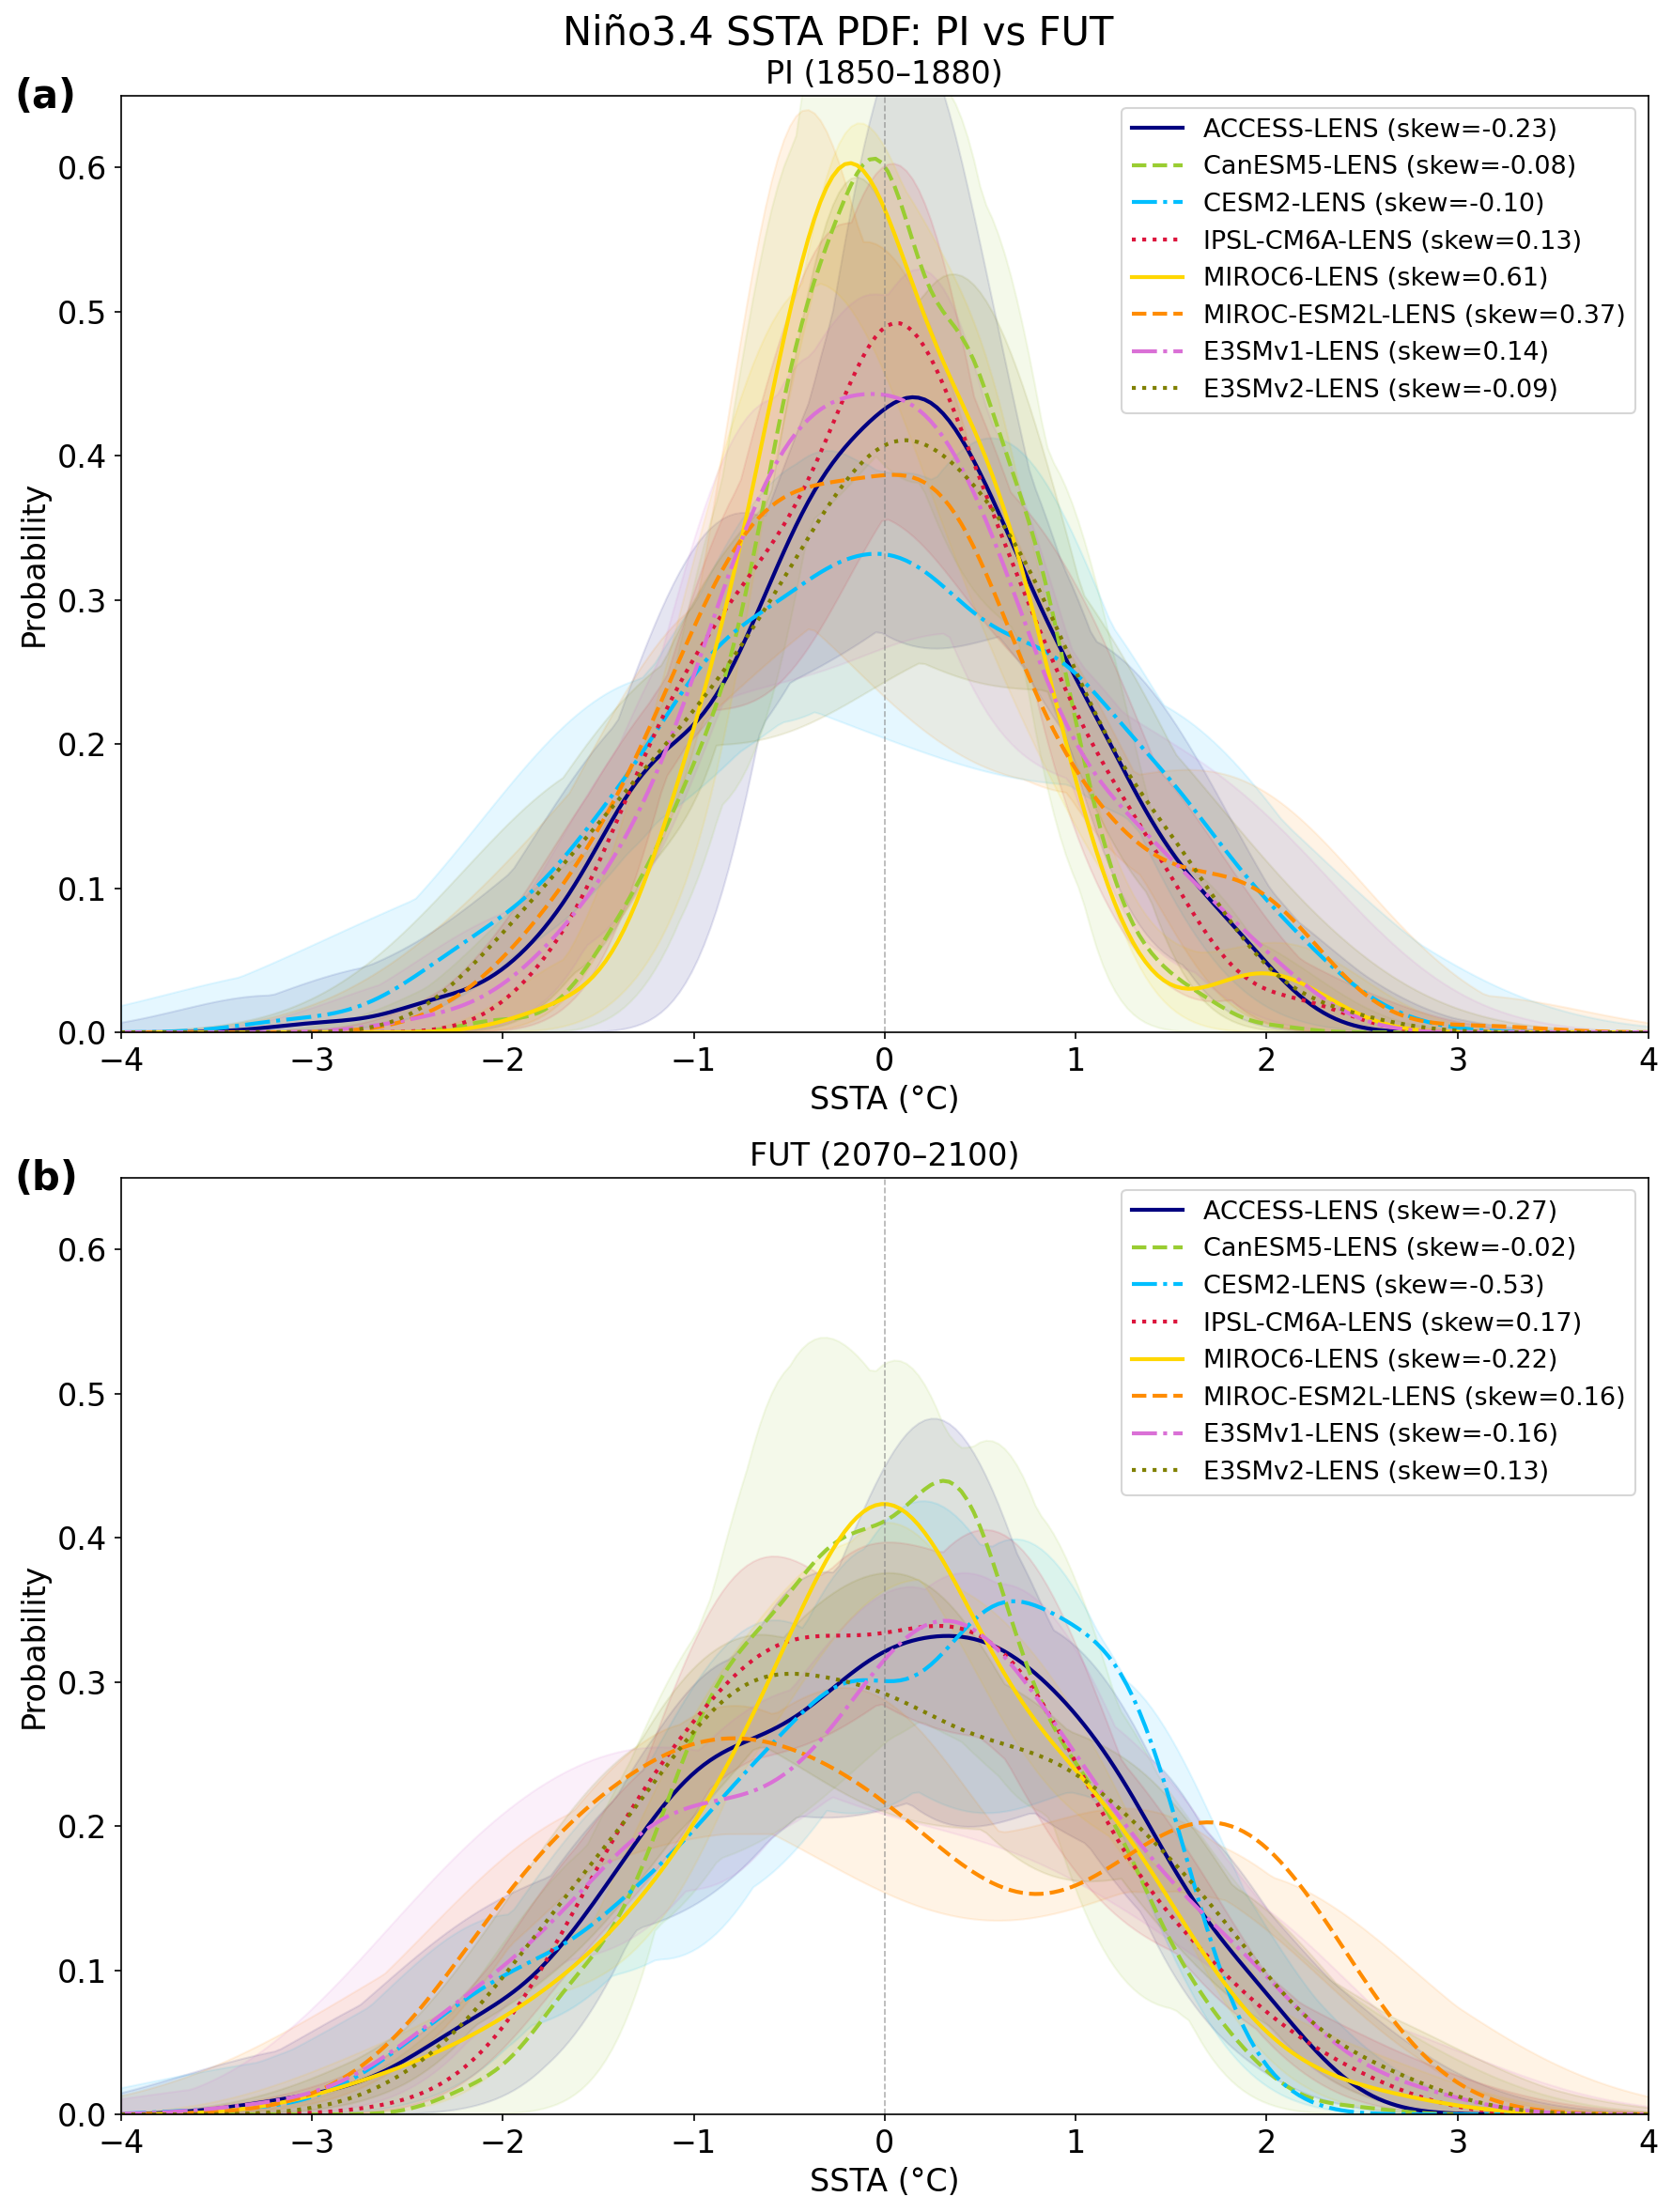

In [10]:
def member_kde_envelope(djf, t1, t2, bins):
    """
    Compute KDE for each member separately, return min/max envelope across members.
    """
    subset = djf.sel(time=slice(t1, t2))
    n_members = subset.shape[0]
    kde_curves = []
    for m in range(n_members):
        vals = subset.isel(member=m).values
        vals = vals[~np.isnan(vals)]
        if len(vals) > 5:
            kde_curves.append(stats.gaussian_kde(vals)(bins))
    kde_curves = np.array(kde_curves)
    return kde_curves.min(axis=0), kde_curves.max(axis=0)

styles=['-','--','-.',':','-','--','-.',':']
fig, axes = plt.subplots(2, 1, figsize=(12, 16))

panels = [
    (axes[0], kdes_pi,  skews_pi,  timespi[0],  timespi[1],  f'PI ({timespi[0]}–{timespi[1]})'),
    (axes[1], kdes_fut, skews_fut, timesfut[0], timesfut[1], f'FUT ({timesfut[0]}–{timesfut[1]})'),
]

for ax, kdes, sks, t1, t2, title in panels:
    for i, ((label, kde), color, style) in enumerate(zip(kdes.items(), colors, styles)):
        ax.plot(bins, kde(bins), lw=2, color=color, linestyle=style,
            label=f'{label} (skew={sks[label]:.2f})')
        env_min, env_max = member_kde_envelope(n34_djf[label], t1, t2, bins)
        ax.fill_between(bins, env_min, env_max, color=color, alpha=0.05)

        # Ensemble spread envelope
        env_min, env_max = member_kde_envelope(n34_djf[label], t1, t2, bins)
        ax.fill_between(bins, env_min, env_max, color=color, alpha=0.05)
    
    ax.axvline(0, color='gray', lw=0.8, ls='--', alpha=0.6)
    ax.set_xlim(-4, 4)
    ax.set_ylim(0, 0.65)
    ax.set_xlabel('SSTA (°C)',fontsize=16)
    ax.set_ylabel('Probability', fontsize=16)
    ax.set_title(title, fontsize=16)
    ax.legend(fontsize=13, loc='upper right')
    ax.tick_params(axis='both', which='major', labelsize=16) 
for ax, label in zip(axes, ['(a)', '(b)']):
    ax.text(-0.07, 1.02, label, transform=ax.transAxes,
            fontsize=20, fontweight='bold', va='top', ha='left')
fig.suptitle('Niño3.4 SSTA PDF: PI vs FUT', fontsize=20)
plt.tight_layout()
plt.savefig('n34_pdf_pi_vs_fut_envelope.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
for ax, kdes, sks, t1, t2, title in panels:
    for i, ((label, kde), color, style) in enumerate(zip(kdes.items(), colors, styles)):
        ax.plot(bins, kde(bins), lw=2, color=color, linestyle=style,
            label=f'{label} (skew={sks[label]:.2f})')
        env_min, env_max = member_kde_envelope(n34_djf[label], t1, t2, bins)
        ax.fill_between(bins, env_min, env_max, color=color, alpha=0.05)

    ax.axvline(0, color='gray', lw=0.8, ls='--', alpha=0.6)
    ax.set_xlim(-4, 4)
    ax.set_ylim(0, 0.65)
    ax.set_xlabel('SSTA (°C)', fontsize=16)
    ax.set_ylabel('Probability', fontsize=16)
    ax.set_title(title, fontsize=16)

    ax.tick_params(axis='both', which='major', labelsize=14)   # <-- tick label size
    ax.legend(fontsize=14, loc='upper right')                  # <-- keep only one legend call